# Fuzzify and LocalModel

Many systems change behaviour with an operating condition: an engine with the
gear, a tyre with the load, a plant with its temperature. One way to model them
is to split the range of the condition into **regions**, give each region a
simple local model, and blend the local models by how much each region applies.
Two layers do this:

- `Fuzzify` turns a scalar signal into **memberships**: one value per region,
  telling how much the signal is in it;
- `LocalModel` builds one local model per region - or per combination of
  regions of several signals - and sums their outputs weighted by the
  memberships.

This tutorial shows the membership functions and their options, then a
local-linear approximation of a curve (with centers that move with training),
gain scheduling of a dynamic model, and scheduling on two variables.

In [1]:
import os

# Pick the Keras backend before nnodely (or Keras) is imported:
# "tensorflow" (the default), "torch" or "jax".
os.environ.setdefault("KERAS_BACKEND", "tensorflow")

import keras
import matplotlib.pyplot as plt
import numpy as np

from nnodely import (
    DataLoader,
    Fir,
    Fuzzify,
    Gaussian,
    Input,
    Linear,
    LocalModel,
    Modely,
    Output,
    Parameter,
    Rectangular,
    Triangular,
    set_seed,
)

set_seed(0)

## Memberships: `Fuzzify`

`Fuzzify(centers, function)` places one membership function on each center.
Called on a scalar stream it gives, per sample, one value per center: the
memberships, a new dim axis of length `len(centers)`.

The three shapes are sized by the neighbouring centers:

- `Triangular`: 1 on its center, down to 0 on the neighbours - inside the range
  of the centers the triangles always add up to 1, a linear interpolation;
- `Rectangular`: 1 up to halfway to each neighbour - exactly one region holds;
- `Gaussian`: a bell, as wide as its gaps.

`plot()` draws them as the layer computes them:

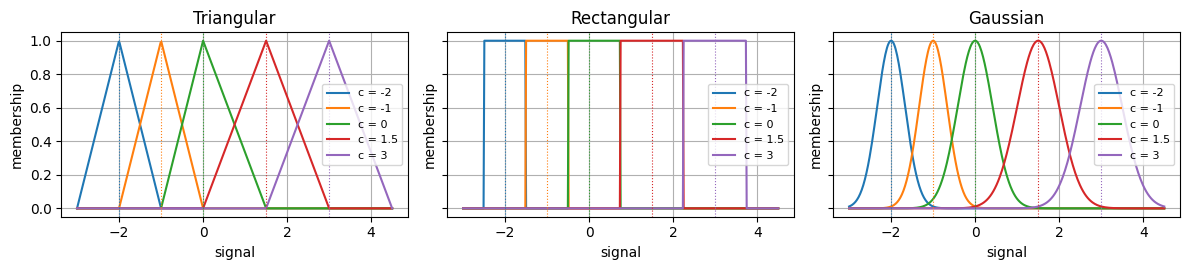

In [2]:
centers = [-2.0, -1.0, 0.0, 1.5, 3.0]
fig, axes = plt.subplots(1, 3, figsize=(12, 2.8), sharey=True)
for ax, function in zip(axes, (Triangular, Rectangular, Gaussian)):
    Fuzzify(centers=centers, function=function).plot(ax=ax)
    ax.set_title(function.__name__)
fig.tight_layout()

In [3]:
speed = Input("speed", tw=1)
memberships = Fuzzify(centers=centers, function=Triangular)([speed])
print(memberships.shape)  # one value per center

probe = Modely("probe", inputs=[speed], outputs=[Output("mu", memberships)]).build()
for value in (-1.5, 0.0, 2.0, 5.0):
    mu = keras.ops.convert_to_numpy(probe(np.full((1, 1, 1), value, "float32"))["mu"])
    print(f"speed {value:5.1f}: {mu.ravel().round(2)}")

Shape(S=(), T=1, D=(5,))
speed  -1.5: [0.5 0.5 0.  0.  0. ]
speed   0.0: [0. 0. 1. 0. 0.]
speed   2.0: [0.   0.   0.   0.67 0.33]
speed   5.0: [0. 0. 0. 0. 0.]


At 5.0, beyond the last center, every triangle is 0: the signal is in no
region. Two options decide what happens there and how the memberships add up:

- `bounds=True` holds the signal between the first and the last center, so that
  beyond the range it belongs to the outer region (`bounds=(low, high)` holds it
  between two numbers);
- `normalize=True` divides the memberships of each sample by their sum, so that
  they always add up to 1.

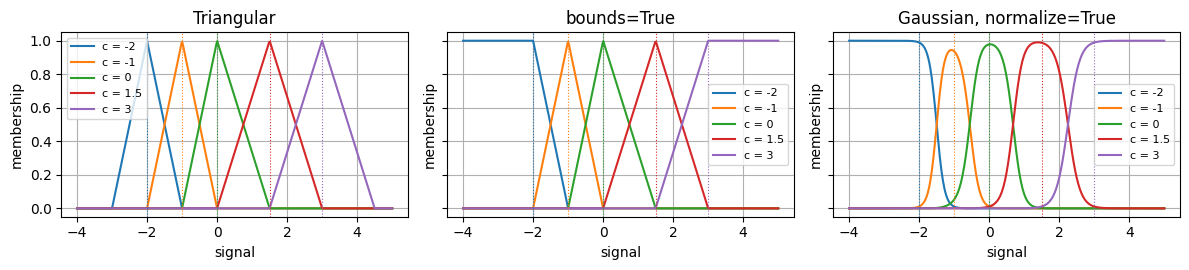

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(12, 2.8), sharey=True)
Fuzzify(centers=centers, function=Triangular).plot(ax=axes[0], x_range=(-4, 5))
Fuzzify(centers=centers, function=Triangular, bounds=True).plot(
    ax=axes[1], x_range=(-4, 5)
)
Fuzzify(centers=centers, function=Gaussian, normalize=True).plot(
    ax=axes[2], x_range=(-4, 5)
)
for ax, title in zip(axes, ("Triangular", "bounds=True", "Gaussian, normalize=True")):
    ax.set_title(title)
fig.tight_layout()

`function` can also be a list, one function per center - here rectangles at the
ends and triangles inside - or any other layer, applied to `x - center`:

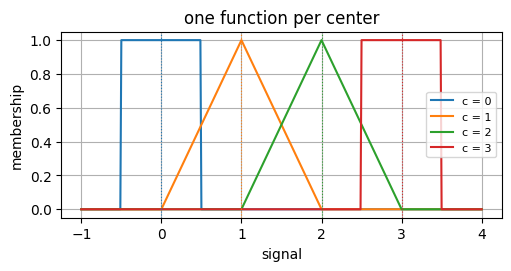

In [5]:
mixed = Fuzzify(
    centers=[0.0, 1.0, 2.0, 3.0],
    function=[Rectangular, Triangular, Triangular, Rectangular],
)
ax = mixed.plot()
ax.set_title("one function per center")
plt.gcf().set_size_inches(5, 2.6)

## Blending local models: `LocalModel`

`LocalModel(input_function)(inputs, [memberships])` builds one local model per
region. `input_function` is a **factory**: called once per region with its
index, it returns that region's layer - here a `Linear`, so each region has its
own line `a_i x + b_i`. The result is

$$y = \sum_i \mu_i(x)\,(a_i\,x + b_i)$$

a Takagi-Sugeno model: local straight lines, blended by the triangles between
the centers.

Here it models an actuator that saturates, $y = \mathrm{clip}(1.6\,x, -2, 2)$,
without knowing where it saturates (at $x = \pm 1.25$). The centers are a
`Parameter`, created frozen for now:

In [6]:
x = Input("x", tw=1)
centers = Parameter("centers", value=[-3.0, -1.5, 0.0, 1.5, 3.0], trainable=False)
fuzzy_x = Fuzzify(centers=centers, function=Triangular)
local = LocalModel(input_function=lambda index: Linear(features=1))([x], [fuzzy_x([x])])

curve = Modely("curve", inputs=[x], outputs=[Output("y", local)])
curve.minimize("fit", "y", Input("y_meas", tw=1))
curve.build()


def saturation(x):
    return np.clip(1.6 * x, -2.0, 2.0)


rng = np.random.default_rng(0)
x_data = rng.uniform(-3.0, 3.0, 2000)
data = DataLoader(curve, source={"x": x_data, "y_meas": saturation(x_data)})
grid = np.linspace(-3.0, 3.0, 400)


def predict():
    return keras.ops.convert_to_numpy(
        curve(grid.reshape(-1, 1, 1).astype("float32"))["y"]
    ).ravel()


def rmse(prediction):
    return np.sqrt(np.mean((prediction - saturation(grid)) ** 2))


curve.train(data, epochs=60, batch_size=64, lr=2e-2, printer=None)
fixed_prediction = predict()
print(
    f"fixed centers   {centers.value_numpy.round(2)}   RMSE {rmse(fixed_prediction):.4f}"
)

fixed centers   [-3.  -1.5  0.   1.5  3. ]   RMSE 0.0591


With the centers fixed, the kinks fall between two centers, where the blend of
two lines cannot follow them. Now the centers are released and trained with the
rest, at a lower learning rate:

In [7]:
centers.unfreeze()
curve.train(data, epochs=60, batch_size=64, lr=5e-3, printer=None)
tuned_prediction = predict()
print(
    f"trained centers {centers.value_numpy.round(2)}   RMSE {rmse(tuned_prediction):.4f}"
)

trained centers [-2.99 -1.27 -0.99  1.25  3.48]   RMSE 0.0028


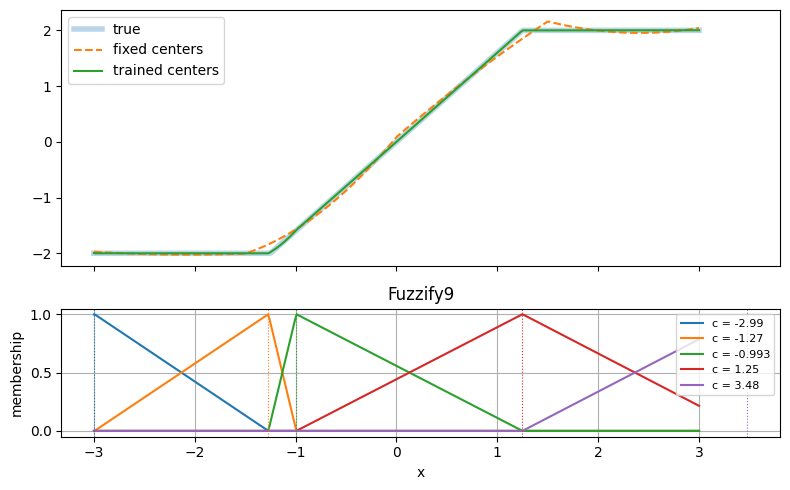

In [8]:
fig, (top, bottom) = plt.subplots(
    2, 1, figsize=(8, 5), sharex=True, height_ratios=[2, 1]
)
top.plot(grid, saturation(grid), lw=4, alpha=0.3, label="true")
top.plot(grid, fixed_prediction, "--", label="fixed centers")
top.plot(grid, tuned_prediction, label="trained centers")
top.legend()
fuzzy_x.plot(ax=bottom, x_range=(-3, 3))  # the memberships, with the trained centers
bottom.set_xlabel("x")
fig.tight_layout()

Two centers moved onto the kinks at $\pm 1.25$, and the error dropped by an
order of magnitude. `plot()` draws the memberships with the parameters' current
values: here the trained ones.

Train the centers in this order: the local models first, the centers frozen,
then the centers too, at a lower learning rate. Trained together from a random
start, the centers can wander off - or cross each other, since moving centers
are used in the order given, never sorted.

## Gain scheduling of a dynamic model

The local models can be anything with weights - here a `Fir`, a dynamic
response. An engine's force answers its torque command through a response that
depends on the gear: one `Fir` per gear, blended by the gear memberships.
`input_function` builds a `Fir` per region, each with weights of its own:

In [9]:
torque = Input("torque", tw=10)
gear = Input("gear", tw=1)
mu_gear = Fuzzify(centers=[1.0, 2.0, 3.0, 4.0], function=Triangular)([gear])
force = LocalModel(
    input_function=lambda index: Fir(features=1, bias=False), name="by_gear"
)([torque], [mu_gear])
engine = Modely("engine", inputs=[torque, gear], outputs=[Output("force", force)])
engine.minimize("force_fit", "force", Input("force_meas", tw=1))
engine.build()
print(force.shape)
engine.models

Shape(S=(), T=1, D=(1,))


┏━━━━━┳━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━┓
┃ idx ┃ model   ┃ inputs                              ┃ outputs ┃ parameters ┃ built ┃
┡━━━━━╇━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━┩
│ 0   │ by_gear │ by_gear_input0, by_gear_activation0 │ by_gear │ 4          │ no    │
└─────┴─────────┴─────────────────────────────────────┴─────────┴────────────┴───────┘

`LocalModel` declares a model of its own, listed among the models it calls,
with 4 `Fir`s - one per gear. Each has learned the response of its gear:

In [10]:
T = 6000
torque_data = np.repeat(rng.uniform(0.0, 1.0, T // 20), 20)
gear_data = np.repeat(rng.integers(1, 5, T // 200), 200).astype(float)
gains = {1: 4.0, 2: 2.5, 3: 1.5, 4: 1.0}  # force per torque, by gear
responses = {
    g: gains[g]
    * np.exp(-np.arange(10) / (2.0 + g))
    / np.exp(-np.arange(10) / (2.0 + g)).sum()
    for g in gains
}
force_data = np.zeros(T)
for t in range(10, T):
    force_data[t] = responses[int(gear_data[t])] @ torque_data[t - 9 : t + 1][::-1]

engine.train(
    DataLoader(
        engine,
        source={"torque": torque_data, "gear": gear_data, "force_meas": force_data},
    ),
    epochs=30,
    batch_size=64,
    lr=1e-2,
    printer=None,
)
steady = {}
for g in (1, 2, 3, 4):
    data = {
        "torque": np.ones((1, 10, 1), "float32"),
        "gear": np.full((1, 1, 1), g, "float32"),
    }
    steady[g] = float(keras.ops.convert_to_numpy(engine(data)["force"]).ravel()[0])
print("steady force per unit torque:", {g: round(v, 2) for g, v in steady.items()})
print("true:                        ", gains)

steady force per unit torque: {1: 4.01, 2: 2.51, 3: 1.5, 4: 1.02}
true:                         {1: 4.0, 2: 2.5, 3: 1.5, 4: 1.0}


Between two gears - gear `2.5` - the triangles blend the two neighbouring
models half and half.

## Scheduling on two variables

With several membership lists, `LocalModel` builds a local model for every
**combination** of regions: 3 speed regions x 2 load regions give 6 local
models, each weighted by the product of its two memberships.

In [11]:
v_in, load = Input("v", tw=1), Input("load", tw=1)
mu_v = Fuzzify(centers=[0.0, 10.0, 20.0], function=Triangular, bounds=True)([v_in])
mu_load = Fuzzify(centers=[0.0, 1.0], function=Triangular, bounds=True)([load])
grip = LocalModel(input_function=lambda index: Linear(features=1))(
    [v_in], [mu_v, mu_load]
)
tyre = Modely("tyre", inputs=[v_in, load], outputs=[Output("grip", grip)]).build()
print("local models:", len([p for p in tyre.parameters if p.name.endswith("kernel")]))

local models: 6


The factory receives the region of each list, `index = (i_speed, i_load)`, so a
local model can depend on where it sits - for example a different structure for
the low-speed regions.

## Summary

| Task | Code |
|---|---|
| Memberships of a scalar | `Fuzzify(centers=[...], function=Triangular)([x])` -> `D=(n,)` |
| Shapes | `Triangular`, `Rectangular`, `Gaussian`, a list of them, or any layer of `x - c` |
| Beyond the centers | `bounds=True` or `bounds=(low, high)` |
| Add up to 1 | `normalize=True` |
| Trainable centers | `centers=Parameter("c", value=[...])`: fit the rest with them frozen first |
| Draw them | `fuzzify.plot(x_range=..., ax=...)` |
| One model per region | `LocalModel(input_function=lambda i: Linear(1))([x], [mu])` |
| Several variables | `LocalModel(...)([inputs], [mu_a, mu_b])`: one model per combination |

Next: [Recurrent models](10_recurrent_loop.ipynb).